# Import Packages/Libraries and Data

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
import seaborn as sns

# text processing libraries
import re #regular expressions, die wir später beim Processing brauchen
import string
import nltk

# Suppress warnings 
import warnings
warnings.filterwarnings('ignore')

In [3]:
pip install --upgrade pandas

Note: you may need to restart the kernel to use updated packages.


In [4]:
pip install openpyxl --upgrade

In [5]:
df=pd.read_excel('AI in Action_Negoisst-Training-Data.xlsx', index_col=0)  

In [6]:
df.head()

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content
ExperimentID,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo..."
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo..."
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ..."
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last..."
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ..."


# 1) EDA

In [8]:
df.shape

(1150, 6)

In [9]:
df.isnull().sum()

NegotiationID    0
SenderID         0
ReceiverID       0
ActionType       0
NegoOutcome      0
Content          0
dtype: int64

In [10]:
#Anzahl der Zeichen
df['Length'] = df['Content'].str.len()
df.head(10)

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length
ExperimentID,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo...",1250
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo...",1254
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ...",1467
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last...",857
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ...",686
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nYour last offer was a great ...",479
2020_12,65172,65159,65162,FinalAccept,FinalAccept,"Dear Mr. Williams, \nthank you for the pleasa...",393
2020_12,65200,65187,65190,Offer,FinalAccept,"Dear InnoVax Team, \nFirst of all, I would lik...",604
2020_12,65200,65190,65187,Counteroffer,FinalAccept,Dear Michael Brown \nNice to meet you! It is a...,383


In [11]:
#Word Count

def word_count(content):
    content_list = content.split()
    return len(content_list)

df['Word_count of negotiation message'] = df['Content'].apply(word_count)
df.head(10)

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length,Word_count of negotiation message
ExperimentID,,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo...",1250,227
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo...",1254,219
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ...",1467,252
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last...",857,157
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ...",686,124
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nYour last offer was a great ...",479,95
2020_12,65172,65159,65162,FinalAccept,FinalAccept,"Dear Mr. Williams, \nthank you for the pleasa...",393,69
2020_12,65200,65187,65190,Offer,FinalAccept,"Dear InnoVax Team, \nFirst of all, I would lik...",604,103
2020_12,65200,65190,65187,Counteroffer,FinalAccept,Dear Michael Brown \nNice to meet you! It is a...,383,70


<Axes: >

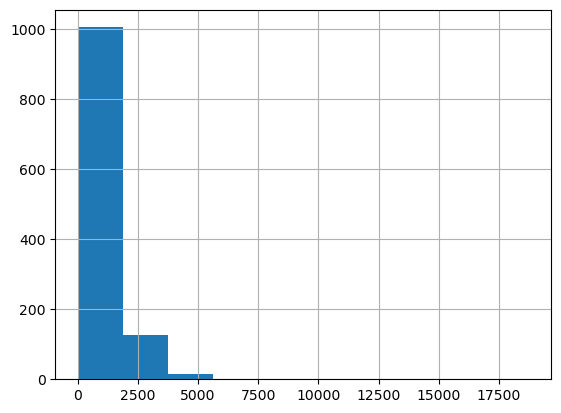

In [12]:
#Histogramm auf der Zeichenebene
df['Content'].str.len().hist()

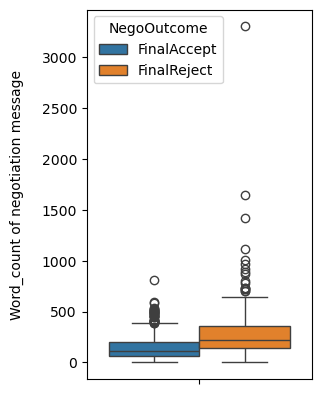

In [13]:
#Visualization der oben generierten Kennzahlen
#Eindruck darüber gewinnen wie sich diese verteilen mit Blick auf Acc/Rej.

def visualize(col):
    
    print()
    plt.subplot(1,2,1)
    sns.boxplot(y=df[col], hue=df['NegoOutcome'])
    plt.ylabel(col, labelpad=12.5)
    plt.show()

#Angefangen vom 7.Element ab 0 zählend, in meinem Fall ab Length anfangen
attributes = df.columns.tolist()[7:]
for column in attributes:
    visualize(column)

In [14]:
#Ein Blick auf die TargetClasss Accept und Reject

In [15]:
df['NegoOutcome'].value_counts()

NegoOutcome
FinalAccept    850
FinalReject    300
Name: count, dtype: int64

In [16]:
accepted_messages = df[df['NegoOutcome']=='FinalAccept']['Content']
accepted_messages.values[1]

"Dear Mr. Brown, \nI am pleased to hear from you.Thank you for your last message. Unfortunately, there are still a few open points that I cannot accept and have to be renegotiated.In the attachments, you can find my first offer.I would aim for the best possible outcome for us both and with this cooperation, we could stop the spread of this disease, therefore I am of course willing to negotiate certain points in open communication. I comprehend your point of view and your situation to need the vaccination very quickly but we from InnoVax need a few more months to be able to produce the requested amount.Concerning the guarantee, we are open to conceding a\xa0Wide\xa0Guarantee\xa0which is a very good level of guarantee. About the price, your suggestion is unfortunately very unacceptable. The development of a vaccine is an expensive process and we make sure that it was made by the best experts from all over the world during long-time research. This is also our big concern and we suggest a 

In [17]:
accepted_messages.count()

850

In [18]:
rejected_messages = df[df['NegoOutcome']=='FinalReject']['Content']
rejected_messages.values[1]

"Dear Dennis Williams, \nThank you for your message! The negotiation will be hard if you consider all topics as very important. But first of all, thank you for your first offer. Our opinions differ on crucial points, I therefore would like to discuss some points regarding the mentioned issues with you. But I am pretty sure, that we can find a good solution for both of us if we concede some issues. In attachment you can find my counteroffer. \nRegarding the delivery time I think your offer of 7 months is quite late. It would be nice if you could explain why your company needs seven months for delivery. You should also consider your competitor from France when making your decision. Your competitor will have a vaccine ready in about six months. Therefore, we would not have a benefit choosing Innovax as our partner when you deliver your vaccine in 7 months. And I think that the start of the field test is important for both of us. So therefore as\xa0Delivery Time\xa0I offer you\xa01 month\x

In [19]:
rejected_messages.count()

300

In [20]:
#LabelTargetVariable 'NegoOutcome' 
from sklearn import preprocessing

'''
le = preprocessing.LabelEncoder()
df['NegoOutcome'] = le.fit_transform(df['NegoOutcome'])
df.NegoOutcome
'''

df['NegoOutcomeLabel'] = df.NegoOutcome.map({'FinalReject':0, 'FinalAccept':1})
df.head()

,NegotiationID,SenderID,ReceiverID,ActionType,NegoOutcome,Content,Length,Word_count of negotiation message,NegoOutcomeLabel
ExperimentID,,,,,,,,,
2020_12,65172,65159,65162,Offer,FinalAccept,"\nDear Mr. Williams, \nI am happy to be respo...",1250,227,1
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nI am pleased to hear from yo...",1254,219,1
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you for your quick ...",1467,252,1
2020_12,65172,65162,65159,Counteroffer,FinalAccept,"Dear Mr. Brown, \nThe concessions of your last...",857,157,1
2020_12,65172,65159,65162,Counteroffer,FinalAccept,"Dear Mr. Williams, \nthank you very much for ...",686,124,1


In [21]:
pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


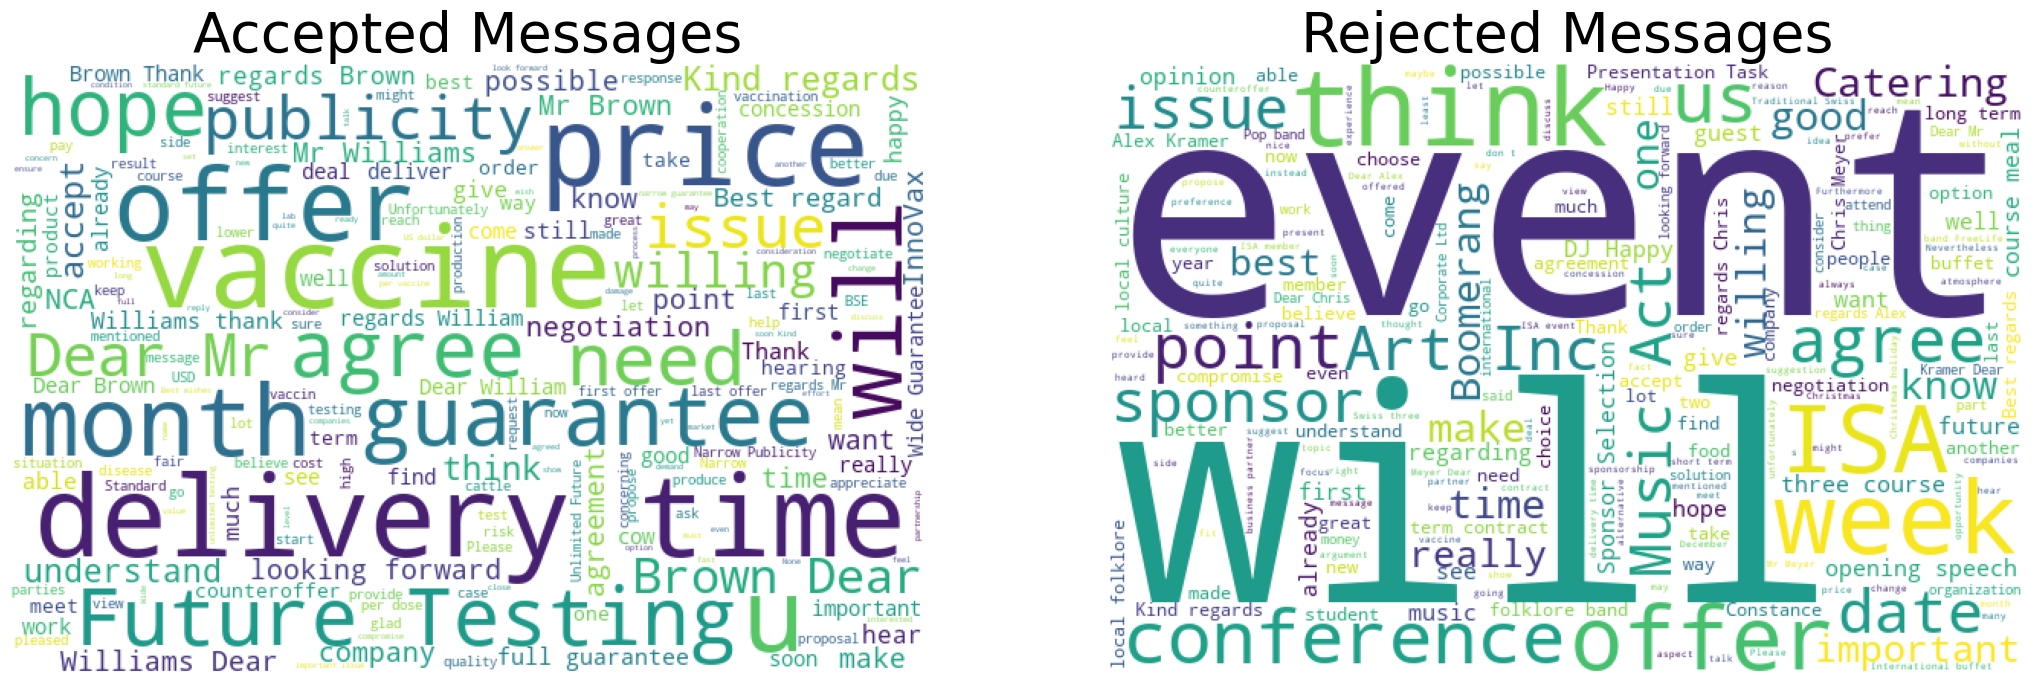

In [22]:
from wordcloud import WordCloud

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=[26, 8])

wordcloud1 = WordCloud( background_color='white',
                        width=600,
                        height=400).generate(" ".join(accepted_messages))
ax1.imshow(wordcloud1)
ax1.axis('off')
ax1.set_title('Accepted Messages',fontsize=40);

wordcloud2 = WordCloud( background_color='white',
                        width=600,
                        height=400).generate(" ".join(rejected_messages))
ax2.imshow(wordcloud2)
ax2.axis('off')
ax2.set_title('Rejected Messages',fontsize=40);

In [23]:
#Anzahl der Nachrichten wo das Wort auftaucht durch Gesamtanzahl
print("The total rate of the word event in rejected messages is: ", 
      sum(rejected_messages.str.contains('event'))/len(rejected_messages))

The total rate of the word event in rejected messages is:  0.6033333333333334
